In [1]:
from glob import glob

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from toolbox import evaluate_combinations, get_freqs, visualize_Category_hist
from toolbox.loading import load_data
from toolbox.visualization import cmap_gradient

# Data statistics

In [2]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    _,
    LesionAssessment,
    label_healthy_vs_cancer,
    label_cancer_vs_lr_hr,
    label_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


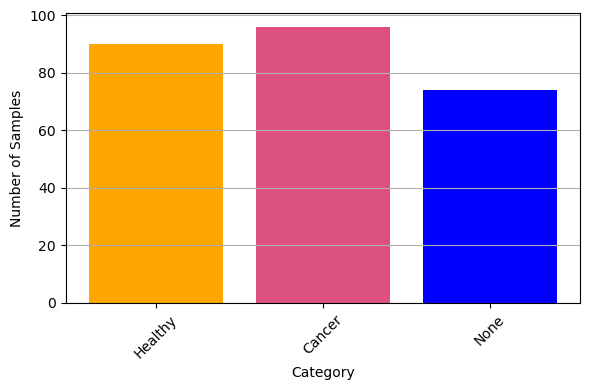

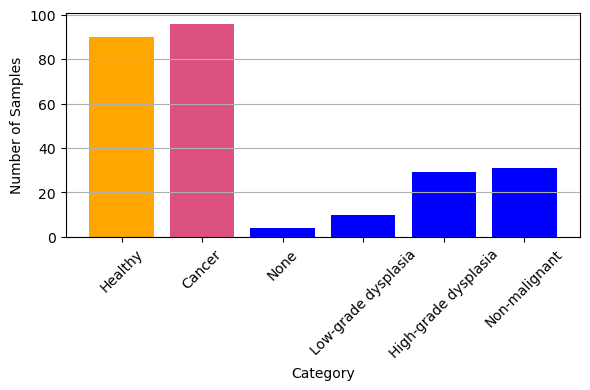

In [7]:
visualize_Category_hist(
    label_healthy_vs_cancer, s_name="results/hist_healthy_vs_cancer.pdf"
)
#visualize_Category_hist(label_cancer_vs_hbd, s_name="results/hist_cancer_vs_hbd.pdf")
visualize_Category_hist(label_MC, s_name="results/hist_MC.pdf")

# Model selection

In [4]:
Fsel = "All"
Msel = "All"

# class_task = "healthy_vs_cancer"
class_task = "cancer_vs_lr_hr"
# class_task = "MC"

df = pd.read_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}_model_HPT.csv")

In [5]:
# Suppose df_avg is your averaged DataFrame
metrics = ["ROC AUC", "Recall", "F1-score"]
df_avg = df.groupby(["Architecture"])[metrics].mean().reset_index()

df_melt = df_avg.melt(
    id_vars=["Architecture"],
    value_vars=metrics,
    var_name="Metric",
    value_name="Score",
)

df_avg = df.groupby(["Architecture"])[metrics].mean().reset_index()

print("Average performance:\n", df_avg)

Average performance:
                  Architecture   ROC AUC    Recall  F1-score
0      DecisionTreeClassifier  0.718424  0.715342  0.715716
1  GradientBoostingClassifier  0.876471  0.808298  0.808107
2                          LR  0.853493  0.800992  0.801018
3                          RF  0.896930  0.818872  0.819065
4                         SVM  0.883983  0.836183  0.836305


C:\Users\f005cgg\AppData\Local\anaconda3\envs\machine_learning\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
C:\Users\f005cgg\AppData\Local\Temp\ipykernel_14164\524524292.py:19: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


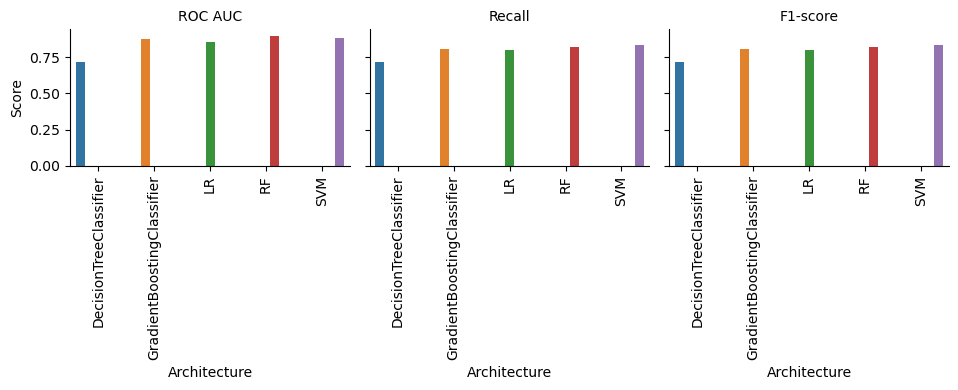

In [6]:
g = sns.catplot(
    data=df_melt,
    x="Architecture",
    y="Score",
    hue="Architecture",
    col="Metric",
    kind="bar",
    height=4,
    aspect=0.8,
)

g.set_titles("{col_name}")
g.set_axis_labels("Architecture", "Score")

# Rotate x tick labels
for ax in g.axes.flat:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.tight_layout()
plt.show()

# Frequency reduction

In [70]:
# class_task = "healthy_vs_cancer"
class_task = "cancer_vs_lr_hr"
# class_task = "MC"

In [7]:
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
fold_rankings_baseline = tmp["fold_rankings_baseline"]
aucs_baseline = tmp["aucs_baseline"]
top_freqs_baseline = tmp["top_freqs_baseline"]
fold_aucs_baseline = tmp["fold_aucs_baseline"].tolist()

ModuleNotFoundError: No module named 'numpy._core'

In [ ]:
def plot_fold_rankings(fold_rankings_dict, top_n_freqs=20, class_task="unnamed"):
    """
    Visualizes fold frequency rankings as heatmaps for multiple ranking sets.

    Parameters:
        fold_rankings_dict : dict
            Dictionary where keys are method names and values are lists of np.arrays (fold rankings).
        top_n_freqs : int
            Number of top composite frequencies to display in the heatmap.
    """
    for name, rankings in fold_rankings_dict.items():
        n_folds = len(rankings)
        n_freqs = len(rankings[0])

        # Composite ranking across folds for sorting
        score_accumulator = np.zeros(n_freqs)
        for fold in rankings:
            for rank, freq_idx in enumerate(fold):
                score_accumulator[freq_idx] += n_freqs - rank

        composite_ranking = np.argsort(score_accumulator)[::-1][:top_n_freqs]

        # Create rank matrix: rows = top freqs, cols = folds
        rank_matrix = np.full((top_n_freqs, n_folds), np.nan)
        for f_idx, fold in enumerate(rankings):
            for i, freq in enumerate(composite_ranking):
                pos = np.where(fold == freq)[0]
                if pos.size > 0:
                    rank_matrix[i, f_idx] = pos[0] + 1  # +1 for 1-based rank

        plt.figure(figsize=(9, 7))
        sns.heatmap(
            rank_matrix,
            annot=True,
            fmt=".0f",
            cmap=cmap_gradient,
            cbar_kws={"label": "Rank Position (lower is better)"},
            xticklabels=[f"Fold {i+1}" for i in range(n_folds)],
            yticklabels=[f"Freq {f+1}" for f in composite_ranking],
            annot_kws={"fontsize": 14},
        )
        plt.xlabel("Fold", fontsize=14)
        plt.ylabel("Top Frequencies", fontsize=14)

        plt.xticks(fontsize=12)  # rotate if needed
        plt.yticks(fontsize=12)
        plt.tight_layout()
        plt.savefig(
            f"results/Fold-wise_frequency_impact_rankings_{name}_{class_task}.pdf",
            bbox_inches="tight",
        )
        plt.show()


fold_rankings_dict = {
    "Baseline": fold_rankings_baseline,
    # "Long-across": fold_rankings_la,
    # "Long-across extend": fold_rankings_lae,
    # "Skip 1": fold_rankings_s1,
}

plot_fold_rankings(fold_rankings_dict, top_n_freqs=31, class_task=class_task)

In [ ]:
# Plot AUC vs number of frequencies
plt.figure(figsize=(6, 3))
plt.plot(
    range(1, 31 + 1),
    np.nanmean([np.array(v) for v in fold_aucs_baseline.values()], axis=0),
    marker="x",
    color="steelblue",
    linewidth=2,
    label="Mean AUC",
)

# Add individual fold lines
for fold_idx in range(5):
    plt.plot(
        range(1, 31 + 1),
        fold_aucs_baseline[fold_idx],
        "o-",
        alpha=0.3,
        label=f"Fold {fold_idx+1}",
    )

plt.xlabel("Number of top frequencies $\mathbf{f}_\mathrm{T}$")
plt.xticks(range(1, 31 + 1, 3))
plt.ylabel("AUC")
plt.grid(True)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"results/baselineaucs_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
freq_idx, freq_list = get_freqs(plot=False)

In [ ]:
top_2 = top_freqs_baseline[:2]
top_3 = top_freqs_baseline[:3]
top_5 = top_freqs_baseline[:5]
top_12 = top_freqs_baseline[:12]

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(freq_list[freq_idx], freq_idx + 1, ".", c="#003F5C", ms=6, label="All")
plt.plot(freq_list[top_2], top_2 + 1, "o", c="#58508D", ms=9.5, label="Top 2")
plt.plot(freq_list[top_3], top_3 + 1, "x", c="#7A5195", ms=9.5, label="Top 3")
plt.plot(freq_list[top_5], top_5 + 1, "X", c="#FF6361", ms=8, label="Top 5")
plt.plot(freq_list[top_12], top_12 + 1, "*", c="#FFA600", ms=8, label="Top 12")
plt.legend()
plt.grid()
plt.xlabel("Frequency (Hz)")
plt.yticks(range(1, 31 + 1, 3))
plt.xscale("log")
plt.ylabel("Frequency index")
plt.tight_layout()
plt.savefig(f"results/freq_topX_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
class_task = "healthy_vs_cancer"
#class_task = "cancer_vs_hbd"
#class_task = "MC"

df_results = pd.read_csv(f"results/freq-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/freq-analysis_{class_task}_params.csv")

In [ ]:
df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

if class_task == "MC":
    fig = plt.figure(figsize=(9.25, 3))
else:
    fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "Mean AUC"}, ax=ax0
)
ax0.set_ylabel(r"Selected frequencies $\mathbf{f}_\mathrm{T}$")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Mean AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Fsel"],
        markersize=8,
        color="black" if row["Fsel"] == "All" else None,
    )
ax1.set_xlabel("Input data points $N_{input}$\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
# ax1.set_xscale('log')

ax1.legend(title="Freq. selection")
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
Fsel_map = {
    "All": "black",
    "Top 2": "#FFA600",
    "Top 3": "#58508D",
    "Top 5": "#7A5195",
    "Top 12": "#DD5182",

}

df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

if class_task == "MC":
    fig = plt.figure(figsize=(9.25, 3))
else:
    fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]
df_pivot = df_pivot.reindex(order)
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "AUC"}, ax=ax0
)
ax0.set_ylabel(r"Selected frequencies $\mathbf{f}_\mathrm{T}$")
ax0.set_xlabel("Trial\n(a)")

# right plot
ax1 = fig.add_subplot(gs[1])
df_merged = pd.merge(df_params, df_results, on="Fsel")
df_summary = (
    df_merged.groupby(["n_params", "Fsel"])["avg. ROC AUC"]
    .agg(["mean", "std"])
    .reset_index()
)
# scatter with error bars
for fsel, group in df_summary.groupby("Fsel"):
    ax1.errorbar(
        group["n_params"],
        group["mean"],
        yerr=group["std"],
        fmt="o",
        capsize=4,
        label=fsel,
        color=Fsel_map.get(fsel, None)
    )
ax1.legend()
ax1.set_xlabel("Input data points $N_{input}$\n(b)")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

for x,y,c in zip(df_merged["n_params"],df_merged["avg. ROC AUC"],df_merged["Fsel"].map(Fsel_map)):
    ax1.plot(
        x,
        y,
        "+",
        color=c,
        markersize=6,
    )
ax1.set_xscale('log')
ax1.legend(title="Freq. selection",framealpha=0.5)
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
df_plot

In [ ]:
df_plot["n_params"] / 239568 * 100

In [ ]:
min(df_plot["avg. ROC AUC"]), max(df_plot["avg. ROC AUC"])

## Statistical impact of $\mathbf{f}_\mathrm{T}$ plot - Choose scoring metrics

In [5]:
from glob import glob

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

metric = "auc"  # Options are auc, f1, acc

files = glob(f"results/FREQ-analysis_*_{metric}_gpu.csv")
dfs = []
for file in files:
    df = pd.read_csv(file)
    dfs.append(df)
df_stats = pd.concat(dfs, ignore_index=True)

df_stats

,Task,rs,Fold,metric,need_proba,max_freqs,fold_top_freq_indices,avg_fold_score,scores_by_n,recall,specificity
0,cancer_vs_lr_hr,0,1,auc,True,31,"[7, 0, 30, 12, 8, 26, 23, 27, 13, 16, 29, 15, ...",0.573517,"[0.5390151515151516, 0.5418602693602694, 0.626...",0.256970,NaN
1,cancer_vs_lr_hr,0,2,auc,True,31,"[30, 7, 0, 29, 12, 8, 13, 16, 28, 26, 9, 27, 1...",0.811070,"[0.73941166257629, 0.7978778228013489, 0.79295...",0.452778,NaN
2,cancer_vs_lr_hr,0,3,auc,True,31,"[30, 7, 0, 12, 29, 13, 8, 28, 16, 25, 9, 21, 2...",0.771362,"[0.6677777777777778, 0.818888888888889, 0.7955...",0.333333,NaN
3,cancer_vs_lr_hr,0,4,auc,True,31,"[30, 27, 0, 29, 12, 28, 13, 20, 8, 16, 25, 23,...",0.679922,"[0.7176576039772634, 0.6975121627598408, 0.654...",0.377778,NaN
4,cancer_vs_lr_hr,0,5,auc,True,31,"[30, 7, 27, 0, 29, 8, 25, 28, 23, 24, 1, 26, 1...",0.742628,"[0.679229797979798, 0.687682379349046, 0.79162...",0.333333,NaN
...,...,...,...,...,...,...,...,...,...,...,...
145,MC,9,1,auc,True,31,"[30, 0, 7, 29, 8, 27, 12, 28, 23, 11, 1, 26, 2...",NaN,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",0.492424,NaN
146,MC,9,2,auc,True,31,"[30, 7, 0, 12, 29, 8, 13, 28, 16, 11, 27, 9, 2...",0.778206,"[0.8007247792329513, 0.7395721033815928, 0.708...",0.434211,NaN
147,MC,9,3,auc,True,31,"[30, 0, 29, 12, 13, 8, 27, 10, 16, 28, 11, 26,...",0.614382,"[0.5604707792207793, 0.7285200453785979, 0.643...",0.387500,NaN
148,MC,9,4,auc,True,31,"[7, 0, 30, 12, 8, 13, 10, 9, 16, 29, 11, 27, 2...",0.582475,"[0.5123088441702572, 0.5062471730270643, 0.558...",0.407005,NaN


# T tests between different frequency selections and 'All'

In [6]:
df_overall = df_stats
mapping_t = {"healthy_vs_cancer": "Task 1", "cancer_vs_lr_hr": "Task 2", "MC": "Task 3"}
mapping_c = {
    "healthy_vs_cancer": "#58508D",
    "cancer_vs_lr_hr": "#FFA600",
    "MC": "#FF6361",
}
df_overall["Color"] = df_overall["Task"].map(mapping_c)
df_overall["Task"] = df_overall["Task"].map(mapping_t)

df_overall

,Task,rs,Fold,metric,need_proba,max_freqs,fold_top_freq_indices,avg_fold_score,scores_by_n,recall,specificity,Color
0,Task 2,0,1,auc,True,31,"[7, 0, 30, 12, 8, 26, 23, 27, 13, 16, 29, 15, ...",0.573517,"[0.5390151515151516, 0.5418602693602694, 0.626...",0.256970,NaN,#FFA600
1,Task 2,0,2,auc,True,31,"[30, 7, 0, 29, 12, 8, 13, 16, 28, 26, 9, 27, 1...",0.811070,"[0.73941166257629, 0.7978778228013489, 0.79295...",0.452778,NaN,#FFA600
2,Task 2,0,3,auc,True,31,"[30, 7, 0, 12, 29, 13, 8, 28, 16, 25, 9, 21, 2...",0.771362,"[0.6677777777777778, 0.818888888888889, 0.7955...",0.333333,NaN,#FFA600
3,Task 2,0,4,auc,True,31,"[30, 27, 0, 29, 12, 28, 13, 20, 8, 16, 25, 23,...",0.679922,"[0.7176576039772634, 0.6975121627598408, 0.654...",0.377778,NaN,#FFA600
4,Task 2,0,5,auc,True,31,"[30, 7, 27, 0, 29, 8, 25, 28, 23, 24, 1, 26, 1...",0.742628,"[0.679229797979798, 0.687682379349046, 0.79162...",0.333333,NaN,#FFA600
...,...,...,...,...,...,...,...,...,...,...,...,...
145,Task 3,9,1,auc,True,31,"[30, 0, 7, 29, 8, 27, 12, 28, 23, 11, 1, 26, 2...",NaN,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",0.492424,NaN,#FF6361
146,Task 3,9,2,auc,True,31,"[30, 7, 0, 12, 29, 8, 13, 28, 16, 11, 27, 9, 2...",0.778206,"[0.8007247792329513, 0.7395721033815928, 0.708...",0.434211,NaN,#FF6361
147,Task 3,9,3,auc,True,31,"[30, 0, 29, 12, 13, 8, 27, 10, 16, 28, 11, 26,...",0.614382,"[0.5604707792207793, 0.7285200453785979, 0.643...",0.387500,NaN,#FF6361
148,Task 3,9,4,auc,True,31,"[7, 0, 30, 12, 8, 13, 10, 9, 16, 29, 11, 27, 2...",0.582475,"[0.5123088441702572, 0.5062471730270643, 0.558...",0.407005,NaN,#FF6361


In [7]:
df_cleaned = df_overall.dropna(subset='Task')
df_cleaned

,Task,rs,Fold,metric,need_proba,max_freqs,fold_top_freq_indices,avg_fold_score,scores_by_n,recall,specificity,Color
0,Task 2,0,1,auc,True,31,"[7, 0, 30, 12, 8, 26, 23, 27, 13, 16, 29, 15, ...",0.573517,"[0.5390151515151516, 0.5418602693602694, 0.626...",0.256970,NaN,#FFA600
1,Task 2,0,2,auc,True,31,"[30, 7, 0, 29, 12, 8, 13, 16, 28, 26, 9, 27, 1...",0.811070,"[0.73941166257629, 0.7978778228013489, 0.79295...",0.452778,NaN,#FFA600
2,Task 2,0,3,auc,True,31,"[30, 7, 0, 12, 29, 13, 8, 28, 16, 25, 9, 21, 2...",0.771362,"[0.6677777777777778, 0.818888888888889, 0.7955...",0.333333,NaN,#FFA600
3,Task 2,0,4,auc,True,31,"[30, 27, 0, 29, 12, 28, 13, 20, 8, 16, 25, 23,...",0.679922,"[0.7176576039772634, 0.6975121627598408, 0.654...",0.377778,NaN,#FFA600
4,Task 2,0,5,auc,True,31,"[30, 7, 27, 0, 29, 8, 25, 28, 23, 24, 1, 26, 1...",0.742628,"[0.679229797979798, 0.687682379349046, 0.79162...",0.333333,NaN,#FFA600
...,...,...,...,...,...,...,...,...,...,...,...,...
145,Task 3,9,1,auc,True,31,"[30, 0, 7, 29, 8, 27, 12, 28, 23, 11, 1, 26, 2...",NaN,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",0.492424,NaN,#FF6361
146,Task 3,9,2,auc,True,31,"[30, 7, 0, 12, 29, 8, 13, 28, 16, 11, 27, 9, 2...",0.778206,"[0.8007247792329513, 0.7395721033815928, 0.708...",0.434211,NaN,#FF6361
147,Task 3,9,3,auc,True,31,"[30, 0, 29, 12, 13, 8, 27, 10, 16, 28, 11, 26,...",0.614382,"[0.5604707792207793, 0.7285200453785979, 0.643...",0.387500,NaN,#FF6361
148,Task 3,9,4,auc,True,31,"[7, 0, 30, 12, 8, 13, 10, 9, 16, 29, 11, 27, 2...",0.582475,"[0.5123088441702572, 0.5062471730270643, 0.558...",0.407005,NaN,#FF6361


In [8]:
import numpy as np
import pandas as pd
import ast
import re

# Parsing function reused from before
def parse_space_separated_array_str(s):
    if not isinstance(s, str):
        return np.array(s)
    s = s.strip()
    if s.startswith('array(') and s.endswith(')'):
        s = s[6:-1].strip()
    if s.startswith('[') and s.endswith(']'):
        inner = s[1:-1].strip()
        inner = re.sub(r'\s+', ',', inner)
        s_fixed = f'[{inner}]'
        try:
            return np.array(ast.literal_eval(s_fixed))
        except:
            parts = inner.split(',')
            return np.array([float(x) for x in parts if x.strip()])
    else:
        s_fixed = re.sub(r'\s+', ',', s)
        try:
            parts = s_fixed.split(',')
            return np.array([float(x) for x in parts if x.strip()])
        except:
            return np.array([])

rows = []
for _, row in df_cleaned.iterrows():
    task = row['Task']
    rs = row['rs']
    fold = row['Fold']
    score_results = parse_space_separated_array_str(row['scores_by_n'])
    top_freq_indices = parse_space_separated_array_str(row['fold_top_freq_indices'])
    max_features = min(31, len(score_results), len(top_freq_indices))
    for fsel_num in range(1, max_features + 1):
        score_value = score_results[fsel_num - 1] if score_results.size >= fsel_num else None
        freq_slice = top_freq_indices[:fsel_num] if top_freq_indices.size >= fsel_num else top_freq_indices
        rows.append({
            'Task': task,
            'rs': rs,
            'Fold': fold,
            'Fsel': fsel_num,
            'score': score_value,
            'freqs': freq_slice.tolist()
        })

df_stats = pd.DataFrame(rows)
# delete rs 9, fold 1 from task 3 (set to NaN)
#print(df_stats[(df_stats['rs'] == 9) & (df_stats['Fold'] == 1) & (df_stats['Task'] == 'Task 3')])
df_stats = df_stats[~((df_stats['rs'] == 9) & (df_stats['Fold'] == 1) & (df_stats['Task'] == 'Task 3'))]
df_stats

,Task,rs,Fold,Fsel,score,freqs
0,Task 2,0,1,1,0.539015,[7.0]
1,Task 2,0,1,2,0.541860,"[7.0, 0.0]"
2,Task 2,0,1,3,0.626835,"[7.0, 0.0, 30.0]"
3,Task 2,0,1,4,0.567795,"[7.0, 0.0, 30.0, 12.0]"
4,Task 2,0,1,5,0.554992,"[7.0, 0.0, 30.0, 12.0, 8.0]"
...,...,...,...,...,...,...
4645,Task 3,9,5,27,0.653286,"[30.0, 0.0, 7.0, 12.0, 29.0, 8.0, 13.0, 16.0, ..."
4646,Task 3,9,5,28,0.648103,"[30.0, 0.0, 7.0, 12.0, 29.0, 8.0, 13.0, 16.0, ..."
4647,Task 3,9,5,29,0.644416,"[30.0, 0.0, 7.0, 12.0, 29.0, 8.0, 13.0, 16.0, ..."
4648,Task 3,9,5,30,0.655404,"[30.0, 0.0, 7.0, 12.0, 29.0, 8.0, 13.0, 16.0, ..."


In [9]:
from scipy.stats import ttest_rel, ttest_ind

# Frequency selections to compare
#fsel_comp = ['Top 2', 'Top 3', 'Top 5', 'Top 12']
# store stats results
results = []
for task in df_stats['Task'].unique():
    df_task = df_stats[df_stats['Task'] == task]
    # get score values from all freqs
    score_all = df_task[df_task['Fsel'] == 31]['score'].values
    # Get all available Fsel values except 'all'
    fsel_values = df_task['Fsel'].unique()
    fsel_values = [f for f in fsel_values if f != 'all']
    for fsel in fsel_values:
        # get score values for current fsel to test
        score_fsel = df_task[df_task['Fsel'] == fsel]['score'].values
        # check that lengths match
        if len(score_all) == len(score_fsel):
            # paired ttest
            t_stat, p_val = ttest_rel(score_fsel, score_all, nan_policy='omit')
        else:
            # unpaired ttest
            print(f"Unequal sample sizes for task {task}, Fsel {fsel} --> unpaired ttest")
            t_stat, p_val = ttest_ind(score_fsel, score_all)
        h_val = 0
        if p_val < 0.05:
            h_val = 1
        results.append({'Task': task, 'Fsel': fsel, 'T-stat': t_stat, 'p-value': p_val, 'h-val': h_val, 'mean score': np.nanmean(score_fsel)})
    # Create dataframe with task results and sort by descending T-stat
    df_task_results = pd.DataFrame(results)
    df_task_results = df_task_results[df_task_results['Task'] == task]
    df_task_results = df_task_results.sort_values(by='T-stat', ascending=False)
    print(f"Results {metric} from {task}:")
    print(df_task_results.to_string(index=False))
    print("\n" + "-"*50 + "\n")

# Optionally create a combined dataframe with all results:
df_results = pd.DataFrame(results)

Results auc from Task 2:
  Task  Fsel    T-stat  p-value  h-val  mean score
Task 2    15  1.083535 0.283874      0    0.702409
Task 2    23  1.010966 0.316999      0    0.700792
Task 2     2  0.976797 0.333468      0    0.704670
Task 2    24  0.867682 0.389798      0    0.699515
Task 2    21  0.596677 0.553470      0    0.698878
Task 2     5  0.591506 0.556901      0    0.700885
Task 2    22  0.500719 0.618811      0    0.698608
Task 2     4  0.412798 0.681556      0    0.700120
Task 2    13  0.359393 0.720845      0    0.698348
Task 2    14  0.344250 0.732131      0    0.698096
Task 2    30  0.223029 0.824440      0    0.696360
Task 2     6  0.204878 0.838517      0    0.697812
Task 2    16  0.039313 0.968801      0    0.696305
Task 2     9  0.026730 0.978784      0    0.696293
Task 2     8 -0.023985 0.980962      0    0.695908
Task 2     7 -0.064558 0.948789      0    0.695589
Task 2    20 -0.084391 0.933089      0    0.695708
Task 2    28 -0.147440 0.883390      0    0.695567
Task 2

Mean score for fsel 31: 0.8802892982912508
Mean score for fsel 31: 0.6961058189254546
Mean score for fsel 31: 0.6542927422148962


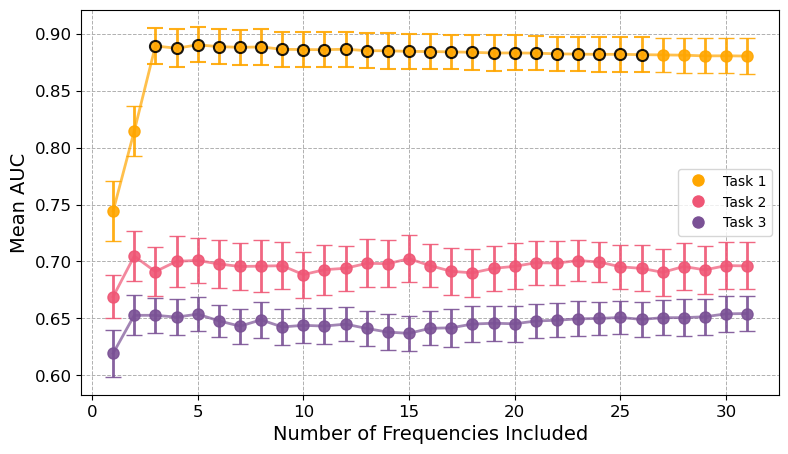

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import sem, t

custom_colors = ['#ffa600', '#ef5675', '#7a5195']

def task_sort_key(task_label):
    match = re.search(r'\d+', task_label)
    return int(match.group()) if match else float('inf')

# Metric label mapping for y-axis
metric_labels = {
    'f1': 'Mean F1 Score',
    'auc': 'Mean AUC',
    'acc': 'Mean Accuracy'
}

tasks = df_stats['Task'].unique()
# Sort so tasks are in numerical order
tasks_sorted = sorted(tasks, key=task_sort_key)
fsel_groups = sorted([f for f in df_stats['Fsel'].unique() if f != 'all'])

fig, ax = plt.subplots(figsize=(9, 5))

for i, task in enumerate(tasks_sorted):
    color = custom_colors[i % len(custom_colors)]  # cycle through colors
    means = []
    fsel_plot = []

    for fsel in fsel_groups:
        score_data = df_stats[(df_stats['Task'] == task) & (df_stats['Fsel'] == fsel)]['score'].values
        if len(score_data) == 0:
            continue
        mean_score = np.mean(score_data)
        n = len(score_data)
        std_err = sem(score_data)
        h = std_err * t.ppf((1 + 0.95) / 2, n - 1) if n > 1 else 0

        res_row = df_results[(df_results['Task'] == task) & (df_results['Fsel'] == fsel)]
        if res_row.empty:
            h_val = 0
            t_stat = None
        else:
            h_val = int(res_row['h-val'].values[0])
            t_stat = res_row['T-stat'].values[0]

        # Determine color: use black if Fsel==31, else task color
        #marker_color = 'black' if fsel == 31 else color
        marker_color = color
        # Edge color bold only if significant and not the black marker (keep black for significance on regular colors)
        if fsel == 31:
            #edge_color = 'black'  # black marker gets black edge
            edge_color = color
            print(f"Mean score for fsel 31: {mean_score}")
        else:
            edge_color = 'black' if h_val == 1 and (t_stat is not None and t_stat > 0) else color

        ax.errorbar(fsel, mean_score, yerr=h, fmt='o', color=marker_color, ecolor=marker_color,
                    elinewidth=2, capsize=6, capthick=2,
                    markersize=8,
                    markeredgecolor=edge_color, markeredgewidth=1.5 if edge_color == 'black' else 1,
                    alpha=0.9)
        means.append(mean_score)
        fsel_plot.append(fsel)

    if len(fsel_plot) > 1:
        ax.plot(fsel_plot, means, color=color, linestyle='-', linewidth=2, alpha=0.7)

ax.set_xlabel('Number of Frequencies Included', fontsize=14)
ax.set_ylabel(metric_labels.get(metric, f'Mean {metric.upper()}'), fontsize=14)
#ax.set_title('Mean AUC with 95% Confidence Interval by Task and Frequency inclusion')
ax.tick_params(axis='both', labelsize=12)

from matplotlib.lines import Line2D
legend_handles = [Line2D([0], [0], marker='o', color='w', label=task,
                         markerfacecolor=custom_colors[i % len(custom_colors)], markersize=10) for i, task in enumerate(tasks_sorted)]
ax.legend(handles=legend_handles)
ax.grid(True, linestyle='--', linewidth=0.7)

# Save figure
plt.savefig(f"results/Freq_reduction_all_tasks_with_CI_{metric}.pdf", bbox_inches='tight')
plt.show()

# Get composite frequency rankings

In [31]:
from collections import defaultdict

# Composite frequency ranking calculation from df_overall
compiled_freq_results = []

for task in df_overall['Task'].unique():
    df_task = df_overall[df_overall['Task'] == task]
    
    total_rows = len(df_task)
    freq_points = defaultdict(float)
    
    for idx, row in df_task.iterrows():
        # Parse fold_top_freq_indices robustly
        freqs = parse_space_separated_array_str(row['fold_top_freq_indices'])
        
        for rank, freq in enumerate(freqs):
            freq_points[freq] += rank
    
    # Average points by total number of rows
    for freq in freq_points:
        freq_points[freq] /= total_rows
    
    # Sort ascending by average points (best first)
    freq_ranking_sorted = sorted(freq_points.items(), key=lambda x: x[1])
    sorted_freqs = [freq for freq, pts in freq_ranking_sorted]
    
    compiled_freq_results.append({
        'Task': task,
        'frequency_ranking': sorted_freqs
    })

df_freq_ranking = pd.DataFrame(compiled_freq_results)

# Get top 4 Fsel groups per Task from df_results
top_fsel_per_task = (
    df_results
    .sort_values(['Task', 'T-stat'], ascending=[True, False])
    .groupby('Task')
    .head(4)                        # top 4 rows per Task by T-stat
    .groupby('Task')['Fsel']        # group again to aggregate
    .apply(list)                    # collect Fsel into list
    .reset_index(name='best_fsel_groups')
)

# Merge top_fsel_groups into composite frequency ranking df by Task
df_final = pd.merge(df_freq_ranking, top_fsel_per_task, on='Task', how='left')
df_final.to_csv("results/task_freq_fsel_summary.csv", index=False)

print(df_final)

     Task                                  frequency_ranking best_fsel_groups
0  Task 2  [30.0, 0.0, 12.0, 29.0, 8.0, 7.0, 27.0, 28.0, ...     [3, 4, 5, 6]
1  Task 1  [30.0, 0.0, 12.0, 27.0, 29.0, 13.0, 8.0, 28.0,...  [29, 30, 28, 6]
2  Task 3  [30.0, 0.0, 12.0, 7.0, 8.0, 29.0, 13.0, 28.0, ...   [30, 4, 7, 10]


Only non-signifcant results is from Top 12 frequencies in Task 2. So we can claim that tuning the included frequencies improves the AUCs

# IIVV pattern reduction

In [29]:
class_task = "healthy_vs_cancer"
#class_task = "cancer_vs_lr_hr"
# class_task = "MC"

In [30]:
df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params.csv")

In [31]:
df_results

,Mask,Trial,avg. ROC AUC
0,All,1,0.534318
1,All,2,0.736461
2,All,3,0.723024
3,All,4,0.715589
4,All,5,0.615200
...,...,...,...
125,Opp. far,6,0.794639
126,Opp. far,7,0.696019
127,Opp. far,8,0.700793
128,Opp. far,9,0.759126


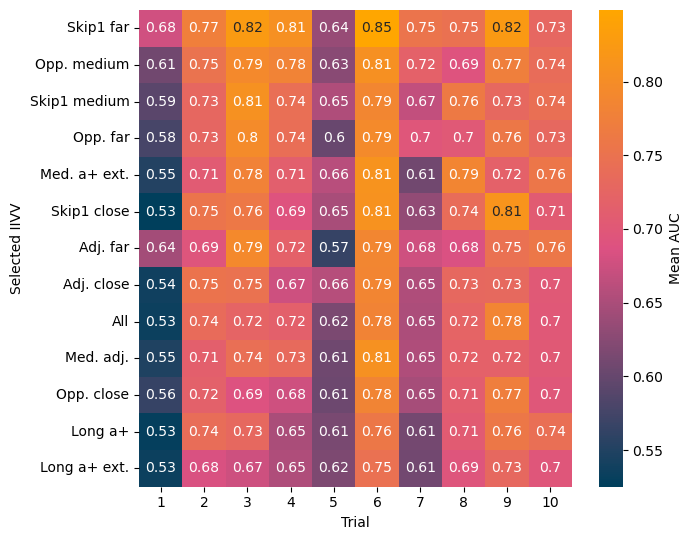

In [23]:
# --- Heatmap figure ---
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

mask_means = df_pivot.mean(axis=1)
# Sort descending by mean ROC AUC
order = mask_means.sort_values(ascending=False).index.tolist()
df_pivot = df_pivot.reindex(order)

fig1, ax0 = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    df_pivot,
    annot=True,
    cmap=cmap_gradient,
    cbar_kws={"label": "Mean AUC"},
    ax=ax0,
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial")
plt.tight_layout()
plt.savefig(f"results/IIVV_sel_heatmap_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [24]:
print("Ranked by best preformance")
print(mask_means[order])

Ranked by best preformance
Mask
Skip1 far       0.762025
Opp. medium     0.728631
Skip1 medium    0.721671
Opp. far        0.712408
Med. a+ ext.    0.708904
Skip1 close     0.707990
Adj. far        0.706734
Adj. close      0.697657
All             0.696668
Med. adj.       0.694568
Opp. close      0.686358
Long a+         0.684119
Long a+ ext.    0.663997
dtype: float64


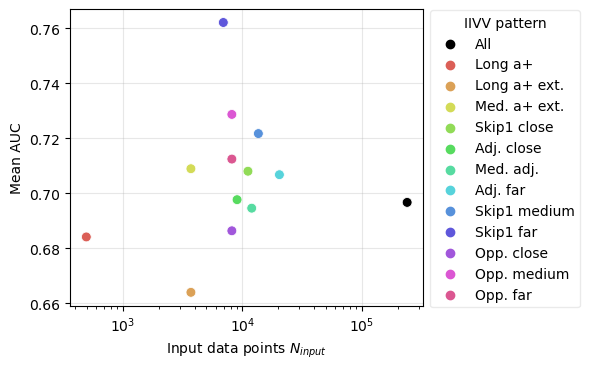

In [25]:
categories = df_plot["Mask"].unique()
base_palette = sns.color_palette(palette="hls", n_colors=len(categories) - 1)
palette = {}
i = 0
for cat in categories:
    if cat == "All":
        palette[cat] = "black"
    else:
        palette[cat] = base_palette[i]
        i += 1

fig2, ax1 = plt.subplots(figsize=(6, 3.8))
sns.scatterplot(
    data=df_plot,
    x="n_params",
    y="avg. ROC AUC",
    hue="Mask",
    palette=palette,
    s=50,
    ax=ax1,
)
ax1.set_xscale("log")
ax1.set_xlabel("Input data points $N_{input}$")
ax1.set_ylabel("Mean AUC")
ax1.grid(alpha=0.3)
ax1.legend(
    title="IIVV pattern", framealpha=0.4, bbox_to_anchor=(1, 1.02), loc="upper left"
)

plt.tight_layout()
plt.savefig(f"results/IIVV_sel_scatter_{class_task}.pdf", bbox_inches="tight")
plt.show()

## Statistical impact of IIVV maskimport numpy as np

In [1]:
from glob import glob

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

metric = "auc"
files = glob(f"results/IIVV-analysis_*_{metric}_gpu.csv")

dfs = []
df_stats = []

for file in files:
    df = pd.read_csv(file)
    dfs.append(df)

df_stats = pd.concat(dfs, ignore_index=True)

mapping_t = {"healthy_vs_cancer": "Task 1", "cancer_vs_lr_hr": "Task 2", "MC": "Task 3"}
mapping_c = {
    "healthy_vs_cancer": "#58508D",
    "cancer_vs_lr_hr": "#FFA600",
    "MC": "#FF6361",
}
df_stats["Color"] = df_stats["Task"].map(mapping_c)
df_stats["Task"] = df_stats["Task"].map(mapping_t)

# Get rid of the exact threshold for each task
df_stats['IIVV'] = df_stats['IIVV'].str.replace(r'^z_threshold:.*', 'z_threshold', regex=True)

In [2]:
df_stats

,Task,Fold,IIVV,rs,metric,score,n_params,need_proba,z_threshold_used,recall_macro,...,f1_macro,balanced_acc,mcc,specificity_sp_macro,recall,sensitivity_sn,specificity_sp,precision,npv,Color
0,Task 2,1,All,0,auc,0.686496,239568,True,NaN,0.273939,...,0.297126,0.273939,0.046892,0.706481,NaN,NaN,NaN,NaN,NaN,#FFA600
1,Task 2,2,All,0,auc,0.869599,239568,True,NaN,0.505556,...,0.430439,0.505556,0.369433,0.796595,NaN,NaN,NaN,NaN,NaN,#FFA600
2,Task 2,3,All,0,auc,0.813600,239568,True,NaN,0.377778,...,0.335116,0.377778,0.212398,0.750000,NaN,NaN,NaN,NaN,NaN,#FFA600
3,Task 2,4,All,0,auc,0.667899,239568,True,NaN,0.451852,...,0.380000,0.451852,0.231988,0.736520,NaN,NaN,NaN,NaN,NaN,#FFA600
4,Task 2,5,All,0,auc,0.834488,239568,True,NaN,0.393939,...,0.350000,0.393939,0.252756,0.733796,NaN,NaN,NaN,NaN,NaN,#FFA600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1045,Task 3,1,Opp. far,4,auc,0.799067,8184,True,NaN,0.412500,...,0.366898,0.412500,0.454057,0.858333,NaN,NaN,NaN,NaN,NaN,#FF6361
1046,Task 3,2,Opp. far,4,auc,0.767650,8184,True,NaN,0.421875,...,0.339646,0.421875,0.386999,0.835938,NaN,NaN,NaN,NaN,NaN,#FF6361
1047,Task 3,3,Opp. far,4,auc,0.775087,8184,True,NaN,0.377924,...,0.319728,0.377924,0.318728,0.822206,NaN,NaN,NaN,NaN,NaN,#FF6361
1048,Task 3,4,Opp. far,4,auc,0.823160,8184,True,NaN,0.426768,...,0.362319,0.426768,0.455058,0.855903,NaN,NaN,NaN,NaN,NaN,#FF6361


T tests between different IIVV groups

In [3]:
# Frequency selections to compare 
iivv_comp = df_stats['IIVV'].unique()
#iivv_comp = [x for x in iivv_comp if x != 'All']    # exclude the "all" pattern
print(iivv_comp)

iivv_counts = {
    'Long a+': 16,
    'Long a+ ext.': 120,
    'Med. a+ ext.': 120,
    'Skip1 close' : 360,
    'Adj. close' :292,
    'Med. adj.' :387,
    'Adj. far' : 660,
    'Skip1 medium': 440, 
    'Skip1 far' : 224,
    'Opp. close': 264,
    'Opp. medium': 264,
    'Opp. far': 264,
    'All': 7728,
    'Z-threshold': 196551,
}
# average number of patterns in z-threshold for each metric
# auc: 182187
# acc: 128960
# f1: 196551


['All' 'Z-threshold' 'Long a+' 'Long a+ ext.' 'Med. a+ ext.' 'Skip1 close'
 'Adj. close' 'Med. adj.' 'Adj. far' 'Skip1 medium' 'Skip1 far'
 'Opp. close' 'Opp. medium' 'Opp. far']


In [4]:
from scipy.stats import ttest_rel, ttest_ind

# store stats results
results = []
for task in df_stats['Task'].unique():
    df_task = df_stats[df_stats['Task'] == task]
    # get score values from all IIVV patterns
    score_all = df_task[df_task['IIVV'] == 'All']['score'].values
    for iivv_set in iivv_comp:
        # get score values for current iivv to test
        score_iivv = df_task[df_task['IIVV'] == iivv_set]['score'].values
        # check that lengths match
        if len(score_all) == len(score_iivv):
            # paired ttest
            t_stat, p_val = ttest_rel(score_iivv, score_all)
        else:
            # unpaired ttest
            print(f"Unequal sample sizes for task {task}, IIVV set {iivv_set} --> unpaired ttest")
            t_stat, p_val = ttest_ind(score_iivv, score_all)
        h_val = 0
        if p_val < 0.05:
            h_val = 1
        results.append({'Task': task, 'IIVV': iivv_set, 'T-stat': t_stat, 'p-value': p_val, 'h-value': h_val, 'mean score': np.mean(score_iivv)})
    # Create a single DataFrame with all task results
    df_results = pd.DataFrame(results)
    # Create dataframe with task results and sort by descending T-stat
    df_task_results = pd.DataFrame(results)
    df_task_results = df_task_results[df_task_results['Task'] == task]
    df_task_results = df_task_results.sort_values(by='mean score', ascending=False)
    print(f"Results {metric} for {task}:")
    print(df_task_results.to_string(index=False))
    print("\n" + "-"*50 + "\n")

Results auc for Task 2:
  Task         IIVV    T-stat  p-value  h-value  mean score
Task 2    Skip1 far  3.526536 0.001725        1    0.806266
Task 2 Med. a+ ext.  5.648374 0.000008        1    0.801835
Task 2 Skip1 medium  3.844155 0.000780        1    0.800873
Task 2  Opp. medium  2.018307 0.054869        0    0.791869
Task 2  Z-threshold  2.651694 0.013966        1    0.790371
Task 2     Adj. far  0.631325 0.533795        0    0.785086
Task 2   Adj. close  0.061194 0.951711        0    0.782260
Task 2    Med. adj.  0.020089 0.984139        0    0.782144
Task 2          All       NaN      NaN        0    0.782074
Task 2     Opp. far -0.169610 0.866739        0    0.781383
Task 2   Opp. close -0.968602 0.342405        0    0.779884
Task 2  Skip1 close -1.616347 0.119090        0    0.777946
Task 2 Long a+ ext. -1.767183 0.089913        0    0.775581
Task 2      Long a+ -2.289450 0.031148        1    0.773139

--------------------------------------------------

Results auc for Task 1:

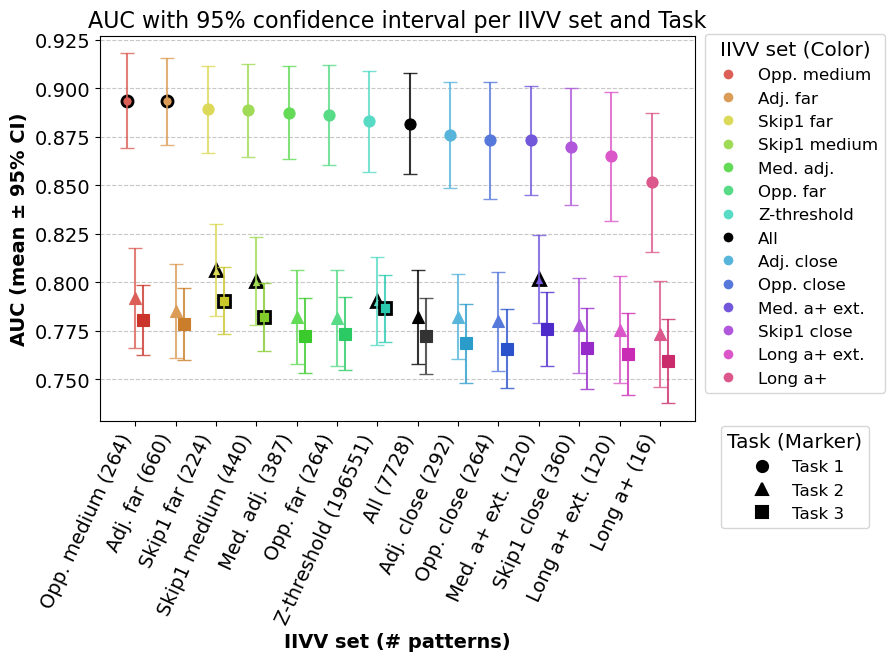

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.stats import sem, t
import re
import colorsys

# Metric label mapping for y-axis and title
metric_labels = {
    'f1': 'F1 Score',
    'auc': 'AUC',
    'acc': 'Accuracy'
}

# Helper: 95% CI calculation
def mean_ci(series, confidence=0.95):
    n = len(series)
    mean = np.mean(series)
    sem_val = sem(series)
    h = sem_val * t.ppf((1 + confidence) / 2., n-1) if n > 1 else 0
    return mean, mean - h, mean + h

def task_sort_key(task_label):
    match = re.search(r'\d+', task_label)
    return int(match.group()) if match else float('inf')

def adjust_lightness(rgb_color, lightness_factor):
    """Adjust the lightness of an RGB color."""
    h, l, s = colorsys.rgb_to_hls(*rgb_color)
    l = max(0, min(1, l * lightness_factor))
    return colorsys.hls_to_rgb(h, l, s)

# Get unique Tasks and Masks
tasks = df_stats["Task"].unique()
masks = df_stats["IIVV"].unique()

# Sort so tasks are in numerical order
tasks_sorted = sorted(tasks, key=task_sort_key)

# Define marker styles per task
marker_styles = ['o', '^', 's']  # change or extend if needed
task_markers = {task: marker_styles[i] for i, task in enumerate(tasks_sorted)}

# Define lightness adjustments per task
task_lightness = {
    tasks_sorted[0]: 1.0,   # Task 1: original
    tasks_sorted[1]: 1.0,   # Task 2: original
    tasks_sorted[2]: 0.8,   # Task 3: 80% lightness
}

# Calculate mean scores for each Mask (IIVV) for Task 1 only
mean_score_task1 = df_stats[df_stats['Task'] == 'Task 1'].groupby('IIVV')['score'].mean()

# Sort mask list by mean score descending (or ascending)
masks_sorted = mean_score_task1.sort_values(ascending=False).index.tolist()

# Use this sorted masks list for x-axis mapping
x_positions = np.arange(len(masks_sorted))
mask_to_x = {m: x for m, x in zip(masks_sorted, x_positions)}

# custom palette
categories = masks_sorted
base_palette_seeds = sns.color_palette("hls", n_colors=len(categories) - 1)
palette = {}
i = 0
for cat in categories:
    if cat == "All":
        palette[cat] = (0, 0, 0)  # black as RGB tuple
    else:
        palette[cat] = base_palette_seeds[i]
        i += 1

fig, ax = plt.subplots(figsize=(10, 5))

# Prepare data for plotting
plot_data = []
for mask in masks:
    for task in tasks_sorted:
        subset = df_stats[(df_stats['IIVV'] == mask) & (df_stats['Task'] == task)]
        if len(subset) == 0:
            continue
        mean, ci_lower, ci_upper = mean_ci(subset['score'])
        plot_data.append({
            'Mask': mask,
            'Task': task,
            'mean': mean,
            'ci_lower': ci_lower,
            'ci_upper': ci_upper
        })

plot_df = pd.DataFrame(plot_data)

# Merge h-value and T-stat into plot_df
plot_df = plot_df.merge(
    df_results[['IIVV', 'Task', 'h-value', 'T-stat']],
    left_on=['Mask', 'Task'],
    right_on=['IIVV', 'Task'],
    how='left'
)

# X-axis positions for each Mask - integer positions
x_positions = np.arange(len(masks_sorted))
mask_to_x = {m: x for m, x in zip(masks_sorted, x_positions)}

# Offset so markers for different tasks don't exactly overlap
offset_map = {tasks_sorted[0]: -0.2, tasks_sorted[1]: 0, tasks_sorted[2]: 0.2}

for idx, row in plot_df.iterrows():
    base_color = palette.get(row['Mask'], (0.5, 0.5, 0.5))  # fallback grey if not found
    
    # Adjust lightness based on task
    task = row['Task']
    if base_color != (0, 0, 0):  # Don't adjust black
        adjusted_color = adjust_lightness(base_color, task_lightness[task])
    else:
        # For black, use different gray levels for Task 3
        if task == tasks_sorted[2]:
            adjusted_color = (0.2, 0.2, 0.2)  # slightly lighter for Task 3
        else:
            adjusted_color = base_color
    
    marker = task_markers.get(row['Task'], 'o')
    x = mask_to_x[row['Mask']] + offset_map[row['Task']]
    y = row['mean']

    # Condition for outlining:
    outline = (row['h-value'] == 1) and (row['T-stat'] > 0)
    edgecolor = 'black' if outline else adjusted_color  # edge black if condition met, else same as facecolor
    edgewidth = 2 if outline else 0.8

    # Plot the mean as a marker, outline if statistically better than baseline
    ax.plot(x, y,
         marker=marker,
         color=adjusted_color,
         markersize=8,
         linestyle='None',
         markeredgecolor=edgecolor,
         markeredgewidth=edgewidth)

    # Plot error bar
    ax.errorbar(
        x, y,
        yerr=[[y - row['ci_lower']], [row['ci_upper'] - y]],
        fmt='none',
        ecolor=adjusted_color,
        capsize=5,
        alpha=0.8
    )

# Create new x tick labels with counts in parentheses
xtick_labels_with_counts = [f"{m} ({iivv_counts.get(m, 0)})" for m in masks_sorted]

# Explicitly set tick positions first, then labels
ax.set_xticks(x_positions)
ax.set_xticklabels(xtick_labels_with_counts, rotation=65, fontsize=14, ha='right')
plt.xticks(x_positions, xtick_labels_with_counts, rotation=65, fontsize=14)
plt.yticks(fontsize=14)

# Get the metric label for display
metric_label = metric_labels.get(metric, metric.upper())

# Customize x-axis ticks and labels
plt.xlabel("IIVV set (# patterns)", fontsize=14, fontweight='bold')
plt.ylabel(f"{metric_label} (mean ± 95% CI)", fontsize=14, fontweight='bold')
plt.title(f"{metric_label} with 95% confidence interval per IIVV set and Task", fontsize=16)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Create legends
from matplotlib.lines import Line2D

# Legend for Masks (color) - use base colors
mask_legend = [Line2D([0], [0], marker='o', color='w', label=mask,
                      markerfacecolor=palette[mask], markersize=8)
               for mask in categories]

# Legend for Tasks (marker styles with lightness indication)
task_legend = [Line2D([0], [0], marker=task_markers[task], color='black', label=task,
                      markersize=8, linestyle='None', markeredgewidth=1.5)
               for task in tasks_sorted]

# Add Mask legend in upper right side of figure
fig.legend(handles=mask_legend,
           title="IIVV set (Color)",
           loc='upper right',
           bbox_to_anchor=(0.91, 0.884),
           borderaxespad=0.,
           fontsize='large',
           title_fontsize='x-large')

# Add Task legend below Mask legend, aligned right
fig.legend(handles=task_legend,
           title="Task (Marker)",
           loc='upper right',
           bbox_to_anchor=(0.894, 0.1),
           borderaxespad=0.,
           fontsize='large',
           title_fontsize='x-large')

plt.subplots_adjust(right=0.72)

# Save figure
plt.savefig(f"results/IIVV_analysis_all_tasks_with_CI_markers_{metric}.pdf", bbox_inches='tight')
plt.show()

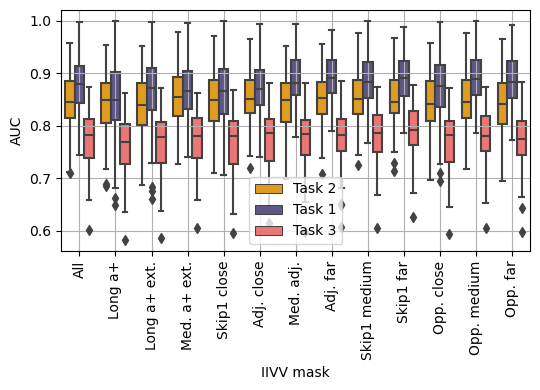

In [106]:
plt.figure(figsize=(5.5, 4))
sns.boxplot(
    data=df_stats,
    x="IIVV",
    y="auc",
    hue="Task",
    palette={
        task: color
        for task, color in zip(df_stats["Task"].unique(), df_stats["Color"].unique())
    },
    #gap=0.1,
)
plt.ylabel("AUC")
plt.grid()
plt.xlabel("IIVV mask")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.savefig(f"results/IIVV-analysis_statistics.pdf", bbox_inches="tight")
plt.show()

___

# Model and parameter tuning results

- Tuning: 4 (best freq. sel) x 4 (best IIVV sel.) = 16 combinations
- Parameter tuning: SVM, RF, LR for baseline


In [40]:
import glob

import numpy as np
import pandas as pd
from toolbox.evaluation import load_top_Fsel_Msel

In [41]:
csv_files = glob.glob("results/LPOCV_*.csv")

if not csv_files:
    print("No matching file name found.")
else:
    for file in csv_files:
        try:
            df = pd.read_csv(file)
            print(f"{file}: {len(df)} Zeilen")
        except Exception as e:
            print(f"Error during loading {file}: {e}")

results\LPOCV_cancer_vs_hbd_All_All_model_HPT.csv: 23 Zeilen
results\LPOCV_cancer_vs_lr_hr_All_All_model_HPT.csv: 25 Zeilen
results\LPOCV_healthy_vs_cancer_All_All_model_HPT.csv: 23 Zeilen
results\LPOCV_healthy_vs_cancer_Top 5_Med. a+ ext._model_HPT.csv: 230 Zeilen
results\LPOCV_MC_All_All_model_HPT.csv: 25 Zeilen
results\LPOCV_tuning_LR_cancer_vs_hbd.csv: 120 Zeilen
results\LPOCV_tuning_LR_healthy_vs_cancer.csv: 160 Zeilen
results\LPOCV_tuning_LR_MC.csv: 120 Zeilen
results\LPOCV_tuning_LR_z_thresh_cancer_vs_hbd.csv: 40 Zeilen
results\LPOCV_tuning_LR_z_thresh_healthy_vs_cancer.csv: 40 Zeilen
results\LPOCV_tuning_LR_z_thresh_MC.csv: 40 Zeilen
results\LPOCV_tuning_RF_cancer_vs_hbd.csv: 120 Zeilen
results\LPOCV_tuning_RF_healthy_vs_cancer.csv: 160 Zeilen
results\LPOCV_tuning_RF_MC.csv: 120 Zeilen
results\LPOCV_tuning_RF_z_thresh_cancer_vs_hbd.csv: 40 Zeilen
results\LPOCV_tuning_RF_z_thresh_healthy_vs_cancer.csv: 40 Zeilen
results\LPOCV_tuning_RF_z_thresh_MC.csv: 40 Zeilen
results\LPOCV_tu

In [44]:
tasks = ["healthy_vs_cancer", "cancer_vs_lr_hr", "MC"]
models = ["SVM", "RF", "LR"]

for class_task in tasks:
    # load frequency selection
    Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)

    for model in models:
        if model == models[0]:
            param_grid = {
                "kernel": ["linear", "poly", "rbf", "sigmoid"],
                "C": np.logspace(
                    -3, 3, 7, dtype=float
                ),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
            }

        elif model == models[1]:
            param_grid = {
                "n_estimators": [100, 300, 500, 800],
                "max_depth": [510, 20, None],
                "max_features": ["sqrt", "log2"],
                "min_samples_split": [2, 5, 10],
                "min_samples_leaf": [1, 2, 4],
            }
        elif model == models[2]:
            param_grid = {
                "C": [0.01, 0.1, 1, 10, 100],
                "max_iter": [100, 1000, 10_000],
            }
        keys = list(param_grid.keys())

        print("\n%----------------------------%")
        print(f"\t{class_task}")
        print(f"\t{model}")

        #df = pd.read_csv(f"results/LPOCV_tuning_{model}_{class_task}.csv")
        pattern = f"results/LPOCV_tuning_{model}*_{class_task}.csv"
        matching_files = glob.glob(pattern)
        
        dfs = []
        for file in matching_files:
            try:
                df_temp = pd.read_csv(file)
                dfs.append(df_temp)
            except Exception as e:
                print(f"Error during loading {file}: {e}")
       
        df = pd.concat(dfs, ignore_index=True)
    
        print("Top Frequencies")
        for Fsel, val in Freq_sel.items():
            print("\t", Fsel, ":", val)
        print("Top IIVVs")
        for Msel in Mask_sel.keys():
            print("\t", Msel)
        print("\n")
        df["hpt_combinations"] = df.apply(
            lambda row: "_".join([str(row[k]) for k in keys]), axis=1
        )

        df["Fsel_Msel"] = df.apply(
            lambda row: "_".join([str(row[k]) for k in ["Fsel", "Msel"]]), axis=1
        )

        result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
        print(result)

        for col in ["hpt_combinations"]:
            print(f"\nColumn: {col}")
            print(df[col].value_counts())

        # get most important tuning comb
        top_hpt = df["hpt_combinations"].value_counts().idxmax()
        print(f"\nMost counted hpt_combinations: {top_hpt}")

        fsel_msel_counts = (
            df.loc[df["hpt_combinations"] == top_hpt, "Fsel_Msel"]
            .value_counts()
            .reset_index()
            .rename(columns={"index": "Fsel_Msel", "Fsel_Msel": "count"})
        )

        print(f"\nRelated Fsel_Msel etries for {top_hpt}")
        print(fsel_msel_counts)

        print("%----------------------------%")


%----------------------------%
	healthy_vs_cancer
	SVM
Top Frequencies
	 Top 1 : [30]
	 Top 2 : [30, 0]
	 Top 3 : [30, 0, 27]
	 Top 4 : [30, 0, 27, 12]
	 Top 5 : [30, 0, 27, 12, 29]
	 Top 6 : [30, 0, 27, 12, 29, 8]
	 Top 7 : [30, 0, 27, 12, 29, 8, 28]
	 Top 8 : [30, 0, 27, 12, 29, 8, 28, 13]
	 Top 9 : [30, 0, 27, 12, 29, 8, 28, 13, 16]
	 Top 10 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26]
	 Top 11 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10]
	 Top 12 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11]
	 Top 13 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25]
	 Top 14 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17]
	 Top 15 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17, 1]
	 Top 16 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17, 1, 24]
	 Top 17 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17, 1, 24, 20]
	 Top 18 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17, 1, 24, 20, 15]
	 Top 19 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17, 1, 24

ValueError: No objects to concatenate

## Pattern and Parameters

In [ ]:
from toolbox.evaluation import load_top_Fsel_Msel

In [ ]:
class_tasks = ["healthy_vs_cancer", "cancer_vs_hbd", "MC"]

for class_task in class_tasks:
    print(class_task, "\n")
    Freq_sel, _ = load_top_Fsel_Msel(class_task)
    print(Freq_sel["Top 12"] + 1)

## ROC plots

In [34]:
glob("results/ROC*.npz")

['results\\ROC_default_cancer_vs_hbd_LR.npz',
 'results\\ROC_default_cancer_vs_hbd_LR_baseline.npz',
 'results\\ROC_default_cancer_vs_hbd_RF.npz',
 'results\\ROC_default_cancer_vs_hbd_RF_baseline.npz',
 'results\\ROC_default_cancer_vs_hbd_SVM.npz',
 'results\\ROC_default_cancer_vs_hbd_SVM_baseline.npz',
 'results\\ROC_default_healthy_vs_cancer_LR.npz',
 'results\\ROC_default_healthy_vs_cancer_LR_baseline.npz',
 'results\\ROC_default_healthy_vs_cancer_RF.npz',
 'results\\ROC_default_healthy_vs_cancer_RF_baseline.npz',
 'results\\ROC_default_healthy_vs_cancer_SVM.npz',
 'results\\ROC_default_healthy_vs_cancer_SVM_baseline.npz',
 'results\\ROC_default_MC_LR.npz',
 'results\\ROC_default_MC_LR_baseline.npz',
 'results\\ROC_default_MC_RF.npz',
 'results\\ROC_default_MC_RF_baseline.npz',
 'results\\ROC_default_MC_SVM.npz',
 'results\\ROC_default_MC_SVM_baseline.npz',
 'results\\ROC_tuned_cancer_vs_hbd_LR.npz',
 'results\\ROC_tuned_cancer_vs_hbd_LR_baseline.npz',
 'results\\ROC_tuned_cancer_vs

In [35]:
np.load(f"results/ROC_tuned_MC_SVM.npz", allow_pickle=True)

NpzFile 'results/ROC_tuned_MC_SVM.npz' with keys: info, MC_save_npz, class_task

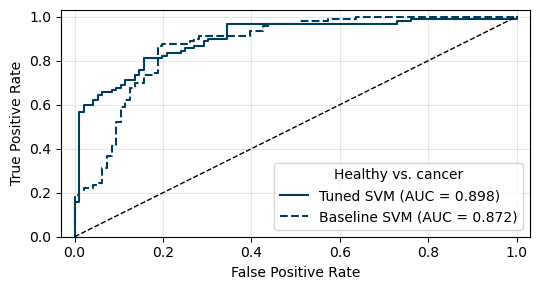

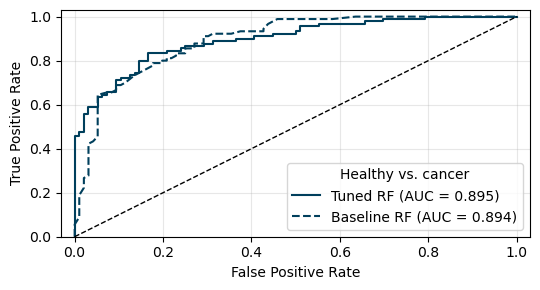

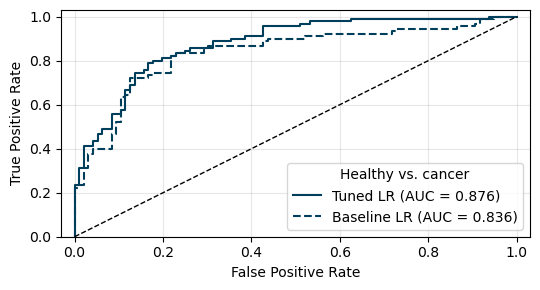

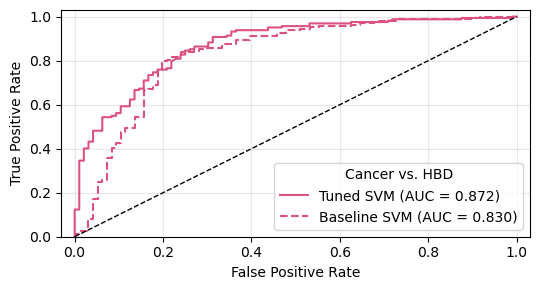

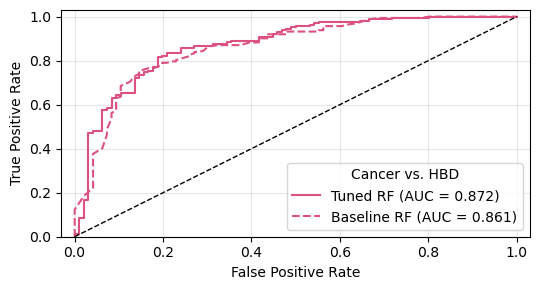

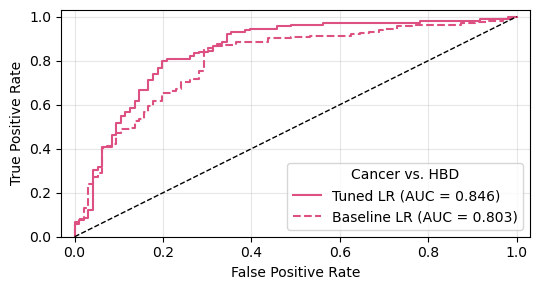

In [41]:
models = ["SVM", "RF", "LR"]
class_tasks = ["healthy_vs_cancer", "cancer_vs_hbd"]

label_roc_plot = {
    "healthy_vs_cancer": "Healthy vs. cancer",
   "cancer_vs_hbd": "Cancer vs. HBD",
    "MC": 'Multiclass'
}


for class_task in class_tasks:
    for model in models:
        tuned = np.load(
            f"results/ROC_tuned_{class_task}_{model}.npz", allow_pickle=True
        )
        baseline = np.load(
            f"results/ROC_default_{class_task}_{model}_baseline.npz", allow_pickle=True
        )

        s_name = f"results/ROC_baseline_tuned_{class_task}_{model}_combined.pdf"

        plt.figure(figsize=(5.5, 3))
        plt.plot(
            tuned["fpr"],
            tuned["tpr"],
            color=tuned["color"].tolist(),
            label= f"Tuned {model} (AUC = {tuned['roc_auc']:.3f})",
        )
        plt.plot(
            baseline["fpr"],
            baseline["tpr"],
            "--",
            color=baseline["color"].tolist(),
            label=f"Baseline {model} (AUC = {baseline['roc_auc']:.3f})",
        )
        plt.plot([0, 1], [0, 1], "k--", linewidth=1)
        plt.xlim([-0.03, 1.03])
        plt.ylim([0.0, 1.03])
        plt.grid()
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.legend(loc="lower right", title=label_roc_plot[class_task])
        plt.grid(alpha=0.3)
        plt.tight_layout()
        if s_name != None:
            plt.savefig(s_name, bbox_inches="tight")

## Timings

In [ ]:
cp = {
    "Baseline": "#FF6361",
    "Tuned": "#A1D99B",
}

In [ ]:
import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

label_roc_plot = {
    "healthy_vs_cancer": "Task 1",
    "cancer_vs_hbd": "Task 2",
    "MC": "Task 3",
}

files = glob.glob("results/timings_default*.npz")

records = []
for f in files:
    data = np.load(f, allow_pickle=True)
    model_type = str(data["model_type"])
    model = str(data["model"])
    class_task = str(data["class_task"])
    timings = data["timings_CV_iter"]

    for t in timings:
        records.append(
            {
                "model_type": model_type,
                "model": model,
                "class_task": label_roc_plot[class_task],
                "timing": t,
            }
        )

df = pd.DataFrame(records)
print(df.head())

df["group"] = df["class_task"] + "\n" + df["model"]
plt.figure(figsize=(5.5, 3))
sns.barplot(data=df, x="group", y="timing", hue="model_type", palette=cp)
plt.xticks(rotation=0)
plt.ylabel("Time per fold in s")
plt.xlabel("")
plt.yscale("log")
plt.legend(title="Model parameter")
plt.grid()
plt.tight_layout()
plt.savefig("results/timings_for_default_param_models.pdf", bbox_inches="tight")

In [ ]:
files = glob.glob("results/timings_tuned*.npz")

records = []
for f in files:
    data = np.load(f, allow_pickle=True)
    model_type = str(data["model_type"])
    model = str(data["model"])
    class_task = str(data["class_task"])
    timings = data["timings_CV_iter"]

    for t in timings:
        records.append(
            {
                "model_type": model_type,
                "model": model,
                "class_task": label_roc_plot[class_task],
                "timing": t,
            }
        )

df = pd.DataFrame(records)
print(df.head())

df["group"] = df["class_task"] + "\n" + df["model"]
plt.figure(figsize=(5.5, 3))
sns.barplot(data=df, x="group", y="timing", hue="model_type", palette=cp)
plt.xticks(rotation=0)
plt.ylabel("Time per fold in s")
plt.xlabel("")
plt.yscale("log")
plt.legend(title="Model parameter")
plt.grid()
plt.tight_layout()
plt.savefig("results/timings_for_tuned_param_models.pdf", bbox_inches="tight")

In [ ]:
files_1 = glob.glob("results/timings_tuned*_SVM.npz")
files_3 = glob.glob("results/timings_tuned*_RF.npz")
files_2 = glob.glob("results/timings_tuned*_LR.npz")
files_4 = glob.glob("results/timings_default*baseline.npz")
files = files_1 + files_2 + files_3 + files_4

records = []
for f in files:
    data = np.load(f, allow_pickle=True)
    model_type = str(data["model_type"])
    model = str(data["model"])
    class_task = str(data["class_task"])
    timings = data["timings_CV_iter"]

    for t in timings:
        records.append(
            {
                "model_type": model_type,
                "model": model,
                "class_task": label_roc_plot[class_task],
                "timing": t,
            }
        )

df = pd.DataFrame(records)
print(df.head())

df["group"] = df["class_task"] + "\n" + df["model"]
plt.figure(figsize=(5.5, 3))
sns.barplot(data=df, x="group", y="timing", hue="model_type", palette=cp)
plt.xticks(rotation=0)
plt.ylabel("Time per fold in s")
plt.xlabel("")
plt.yscale("log")
plt.legend(title="Model parameter")
plt.grid()
plt.tight_layout()
plt.savefig(
    "results/timings_for_tuned_vs_default_param_models.pdf", bbox_inches="tight"
)

## Visualize IIVV mask

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from toolbox import Masking

In [ ]:
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

In [ ]:
# load masking selection
Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}

In [ ]:
mask.prints = False


def plot_Mask(mask, mode="horizontal", title=None, s_name=None):

    if mode == "horizontal":
        plt.figure(figsize=(6, 2.2))
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 0],
            ".",
            markersize=1,
            label="$I_0$",
        )
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 1],
            ".",
            markersize=1,
            label="$I_1$",
        )
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 2],
            ".",
            markersize=1,
            label="$V_0$",
        )
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 3],
            ".",
            markersize=1,
            label="$V_1$",
        )
        plt.xlabel("IIVV index")
        plt.ylabel("Electrode no.")
        plt.grid()
        plt.legend()
        plt.tight_layout()
        if title:
            plt.title(title)
        if s_name != None:
            plt.savefig(s_name, bbox_inches="tight")
        plt.show()
    if mode == "vertical":
        plt.figure(figsize=(2, 6))
        plt.plot(
            mask.IIVV[mask.mask][:, 0],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$I_0$",
        )
        plt.plot(
            mask.IIVV[mask.mask][:, 1],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$I_1$",
        )
        plt.plot(
            mask.IIVV[mask.mask][:, 2],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$V_0$",
        )
        plt.plot(
            mask.IIVV[mask.mask][:, 3],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$V_1$",
        )
        plt.ylabel("IIVV index")
        plt.xlabel("Electrode no.")
        # plt.yticks(ticks=np.arange(len(mask.mask)),labels=np.arange(len(mask.mask)))
        plt.grid()
        plt.legend()
        plt.tight_layout()
        if title:
            plt.title(title)
        if s_name != None:
            plt.savefig(s_name, bbox_inches="tight")
        plt.show()

In [ ]:
for Msel in Mask_sel:
    mask.IIVV_mask(Mask_sel[Msel], plot=False)
    plot_Mask(
        mask,
        mode="horizontal",
        title=None,
        s_name=f"results/IIVV_pattern_{Mask_sel[Msel]}.pdf",
    )

In [ ]:
caption_names = {
    "all": r"\textit{All}",
    "vv_long_across": r"\textit{Long a+}",
    "vv_long_across_extended": r"\textit{Long a+ ext.}",
    "vv_medium_across_extended": r"\textit{Med. a+ ext.}",
    "vv_distance_close_skip_1": r"\textit{Skip1 far}",
    "adjacent_close": r"\textit{Opp. close}",
    "vv_distance_medium_adj": r"\textit{Opp. medium}",
    "adjacent_far": r"\textit{Opp. far}",
    "skip1_medium": r"\textit{Adj. close}",
    "skip1_far": r"\textit{Skip1 close}",
    "opposite_close": r"\textit{Med. adj.}",
    "opposite_medium": r"\textit{Skip1 medium} ",
    "opposite_far": r"\textit{Adj. far}",
}

with open("results/IIVVlatex.txt", "w", encoding="utf-8") as f:
    for values in Mask_sel.values():
        f.write(r"\begin{figure}[H]" + "\n")
        f.write(r"    \centering" + "\n")
        f.write(
            r"    \includegraphics[width=0.8\columnwidth]{figures/IIVVmasks/IIVV_pattern_"
            + f"{values}"
            + r".pdf}"
            + "\n"
        )
        f.write(r"    \caption{IIVV mask " + f"{caption_names[values]}" + r"}" + "\n")
        f.write(r"    \label{appendix:fig:IIVV:" + f"{values}" + r"}" + "\n")
        f.write(r"\end{figure}" + "\n\n")

___